In [252]:
from qiskit import *
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime
import time 



In [253]:

def get_xxz_chain_hamiltonian_dict(n_qubits: int, Delta_ZZ: float) -> dict:
    """
    Construct a dictionary representing the XXZ chain Hamiltonian.
    
    """
    # Create a path graph for the 1D chain
    sites = nx.path_graph(n_qubits)
    
    # Coefficients for the interaction terms
    coeff_xxyy = 1
    coeff_zz   = Delta_ZZ 
    
    # Dictionary to hold the Pauli term and its coefficient
    hamiltonian_dict = {}

    for edge in sites.edges:
        i, j = edge
        
        # For each Pauli type, we create a list that represents an n_qubit operator.
        for op, coeff in [('X', coeff_xxyy), ('Y', coeff_xxyy), ('Z', coeff_zz)]:
            # Start with the identity on all qubits.
            pauli_list = ['I'] * n_qubits
            # Place the Pauli operator on qubit i and qubit j.
            pauli_list[i] = op
            pauli_list[j] = op
            # Convert the list to a tuple so it can be used as a dictionary key.
            key = ''.join(pauli_list)
            
            # Sum the coefficient if the same Pauli string appears from overlapping edges.
            if key in hamiltonian_dict:
                hamiltonian_dict[key] += coeff
            else:
                hamiltonian_dict[key] = coeff

    return hamiltonian_dict
print(get_xxz_chain_hamiltonian_dict(3,0.5))
def get_transverse_Ising_hamiltonian_dict(n_qubits: int, g, J) -> dict:
    """
    The Hamiltonian on pair (i,j) is
    -J(Z_i Z_j) + g(X_i + X_j)
    """
    # Create a path graph for the 1D chain
    sites = nx.path_graph(n_qubits)
    
    # Coefficients for the interaction terms
    coeff_x = g
    coeff_zz   = -J
    
    # Dictionary to hold the Pauli term and its coefficient
    hamiltonian_dict = {}

    for edge in sites.edges:
        i, j = edge
        
        op, coeff = ('Z', coeff_zz)
        pauli_list = ['I'] * n_qubits
        # Place the Pauli operator on qubit i and qubit j.
        pauli_list[i] = op
        pauli_list[j] = op
        # Convert the list to a tuple so it can be used as a dictionary key.
        key = ''.join(pauli_list)
        
        # Sum the coefficient if the same Pauli string appears from overlapping edges.
        if key in hamiltonian_dict:
            hamiltonian_dict[key] += coeff
        else:
            hamiltonian_dict[key] = coeff
    for i in range(n_qubits):
        op, coeff = ('X',coeff_x)
        pauli_list = ['I'] * n_qubits
        pauli_list[i] = op
        key = ''.join(pauli_list)
        
        # Sum the coefficient if the same Pauli string appears from overlapping edges.
        if key in hamiltonian_dict:
            hamiltonian_dict[key] += coeff
        else:
            hamiltonian_dict[key] = coeff

    return hamiltonian_dict
print(get_transverse_Ising_hamiltonian_dict(3,1,1.2))

{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'ZZI': -1.2, 'IZZ': -1.2, 'XII': 1, 'IXI': 1, 'IIX': 1}


In [254]:

def exp_Z(qc, qr, pauli_idx, t=1) -> None:
    """
    Implementation of exp(iZZ...Zt) on qubits in pauli_idx, where t is the parameter.
    Adds to input circuit.

    """
    # the first CNOTs
    for i in range(len(pauli_idx) - 1):
        qc.cx(qr[pauli_idx[i]], qr[pauli_idx[i + 1]])

    # Rz gate
    qc.rz(-2 * t, qr[pauli_idx[-1]])

    # the second CNOTs
    for i in reversed(range(len(pauli_idx) - 1)):
        qc.cx(qr[pauli_idx[i]], qr[pauli_idx[i + 1]])
  
def exp_pauli(pauli, qr, t=1) -> QuantumCircuit:
    """
    The qc for the exp(i P t), where P is the Pauli term, 
    t is the parameter.

    """
    
    pauli_qc = QuantumCircuit(qr)
    pre_post_qc = QuantumCircuit(qr)
    pauli_idexes = []

    for i in range(len(qr)):
        if pauli[i] == 'I':
            continue
        elif pauli[i] == 'Z':
            pauli_idexes.append(i)
        elif pauli[i] == 'X':
            pre_post_qc.h(qr[i])
            pauli_idexes.append(i)
        elif pauli[i] == 'Y':
            pre_post_qc.u(np.pi/2,np.pi / 2, np.pi / 2, qr[i])
            pauli_idexes.append(i)

    pauli_qc = pauli_qc.compose(pre_post_qc)
    exp_Z(pauli_qc, qr, pauli_idexes, t)
    pauli_qc = pauli_qc.compose(pre_post_qc)

    return pauli_qc 
def hamiltonian_simulation_FO_trotter(hamiltonian, qr, N, t=1):
    """
    The implementation of exp((-)iHt) (First Order), where H is the Hamiltonian 
    operator, t is the parameter.

    """
    # print(hamiltonian)
    delta_t = t / N
    exp_hamiltonian = QuantumCircuit(qr)
    exp_delta_t = QuantumCircuit(qr)

    for pauli in hamiltonian:
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t))

    for i in range(N):
        exp_hamiltonian = exp_hamiltonian.compose(exp_delta_t)

    return exp_hamiltonian

def hamiltonian_simulation_SO_trotter(hamiltonian, qr, N, t=1):
    """
    The implementation of exp((-)iHt) (Second Order), where H is the Hamiltonian 
    operator, t is the parameter.

    """
    
    delta_t = t / N
    exp_hamiltonian = QuantumCircuit(qr)
    exp_delta_t = QuantumCircuit(qr)

    for pauli in hamiltonian:
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t/2))
    for pauli in reversed(list(hamiltonian)):
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t/2))

    for i in range(N):
        exp_hamiltonian =exp_hamiltonian.compose(exp_delta_t)

    return exp_hamiltonian


def _trotter_step(hamiltonian, qr, h: float, order: int, p: int = 2) -> QuantumCircuit:
    """
    Build a single Suzuki–Trotter step S_order(h) of even order 'order'.
    Recurses down to order=2 (Strang splitting).
    https://arxiv.org/pdf/2211.02691 3.1.1 'Suzuki's method'

    """
    if order == 2:
        # Strang / second order:
        circ = QuantumCircuit(qr)
        # half‑step forward
        for pauli, weight in hamiltonian.items():
            circ = circ.compose(exp_pauli(pauli, qr, -weight * h/2))
        # half‑step backward
        for pauli, weight in reversed(list(hamiltonian.items())):
            circ = circ.compose(exp_pauli(pauli, qr, -weight * h/2))
        return circ

    # otherwise build S_{order} from S_{order-2}
    n = order - 2
    # Suzuki “p=2” coefficient:
    s = 1.0 / (2*p - (2*p)**(1.0/(n+1)))
    # recursive pieces
    S_small = _trotter_step(hamiltonian, qr, s*h,     order-2, p)
    S_mid   = _trotter_step(hamiltonian, qr, (1-2*p*s)*h, order-2, p)

    # assemble:  (S_small)^p · S_mid · (S_small)^p
    circ = QuantumCircuit(qr)
    for _ in range(p):
        circ = circ.compose(S_small)
    circ = circ.compose(S_mid)
    for _ in range(p):
        circ = circ.compose(S_small)
    return circ

def hamiltonian_simulation_nth_order(hamiltonian, qr, N: int, t: float = 1.0, order: int = 2):
    """
    Full simulation exp(-i H t) via r=N trotter steps of size h=t/N,
    using a 2nd, 4th, 6th, … order Suzuki–Trotter decomposition.

    """
    
    if order < 2 or order % 2 != 0:
        raise ValueError(f"`order` must be 1 or even integer ≥ 2 (got order:{order}")
    h = t / N
    # build one step S_order(h)
    step = _trotter_step(hamiltonian, qr, h, order)

    # repeat it N times
    circ = QuantumCircuit(qr)
    for _ in range(N):
        circ = circ.compose(step)
    return circ


In [255]:
def get_ising_circ_FO(n: int, J: float, g: float, t: float, N: int):
  ham_ising = get_transverse_Ising_hamiltonian_dict(n,g,J)
  qr_ising = QuantumRegister(n)
  qc_ising = hamiltonian_simulation_FO_trotter(ham_ising,qr_ising,N,t)
  return qc_ising
def get_ising_circ_SO(n: int, J: float, g: float, t: float, N: int):
  ham_ising = get_transverse_Ising_hamiltonian_dict(n,g,J)
  qr_ising = QuantumRegister(n)
  qc_ising = hamiltonian_simulation_SO_trotter(ham_ising,qr_ising,N,t)
  return qc_ising

def get_ising_circ_nth_order(n,J,g,t,N,order):

  ham_ising = get_transverse_Ising_hamiltonian_dict(n,g,J)
  qr_ising = QuantumRegister(n)
  if order == 1:
    qc_ising = get_ising_circ_FO(n,J,g,t,N)
  else:
    qc_ising = hamiltonian_simulation_nth_order(ham_ising,qr_ising,N,t,order)
  return qc_ising
def get_xxz_circ_FO(n: int, Delta_ZZ:float, t: float, N: int):
  ham_xxz = get_xxz_chain_hamiltonian_dict(n,Delta_ZZ)
  qr_xxz = QuantumRegister(n)
  qc_xxz = hamiltonian_simulation_FO_trotter(ham_xxz,qr_xxz,N,t)
  return qc_xxz


In [256]:
n = 5
Delta_ZZ = 0.5
g = 1
J = 1.2
t=1
N=100

In [257]:
import numpy as np
### QLIB IS A LIBRARY FOR QUANTUM DYNAMICS SIMULATION https://github.com/ishaanganti/qlib ###
from qlib.operators import * 
from qlib import oper, qprint
from qlib.utils import tensor
from qlib.states import state
from qlib import ket
from scipy.linalg import expm

def time_evolve_operator(H: oper, t: float):
    '''
    Returns the time evolution operator given a TIME-INDEPENDENT
    Hamiltonian H and a time t. The output is an 'oper' object
    per qlib classes.  
    '''
    H = H.to_matrix()
    U = expm(-1j * H * t)
    return oper(U)

def get_xxz_hamiltonian(n_qubits: int, delta: float) -> oper:
    '''
    Creates the Heisenberg XXZ Hamiltonian using qlib. 
    '''
    H_xxz = zeros(2**n_qubits)
    for k in range(n_qubits - 1):
        left_ids = identity(2**k)
        right_ids = identity(2**(n_qubits - k - 2))
        H_xxz += tensor(left_ids, pauli_x(), pauli_x(), right_ids)
        H_xxz += tensor(left_ids, pauli_y(), pauli_y(), right_ids)
        H_xxz += delta * tensor(left_ids, pauli_z(), pauli_z(), right_ids)
    return H_xxz

def get_ising_hamiltonian(n_qubits: int, J: float, g: float):
    '''
    Creates the Ising Hamiltonian using qlib. 
    '''
    H_ising = zeros(2**n_qubits)
    for k in range(n_qubits - 1):
        left_ids = identity(2**k)
        right_ids = identity(2**(n_qubits-k-2))
        H_ising += -J * tensor(left_ids, pauli_z(), pauli_z(), right_ids)
    for k in range(n_qubits):
        left_ids = identity(2**k)
        right_ids = identity(2**(n_qubits-k-1))
        H_ising += g * tensor(left_ids, pauli_x(), right_ids)
    return H_ising

def get_true_ising_state(n,J,g,t):
    H_ising = get_ising_hamiltonian(n, J, g)
    psi0 = state(2**n, 0) 
    true_ising_state = time_evolve_operator(H_ising, t) * psi0
    return true_ising_state

def get_true_ising_energy(n, J, g, t):
    # build the Hamiltonian and exact state
    H = get_ising_hamiltonian(n, J, g)
    psi_t = get_true_ising_state(n, J, g, t)
    
    # pull out the raw arrays
    H_mat   = H.to_matrix()           # 2^n × 2^n numpy array
    psi_vec = psi_t.vector            # length‑2^n complex numpy array

    # expectation value <psi|H|psi>
    E = np.vdot(psi_vec, H_mat.dot(psi_vec))
    return np.real(E)


print(get_true_ising_energy(5,J,g,t))
# psi0 = state(2**n, 0) 

# # hamiltonians
# H_xxz = get_xxz_hamiltonian(n, Delta_ZZ)
# print(Delta_ZZ)
# H_ising = get_ising_hamiltonian(n, J, g)

# # time evolved XXZ state
# true_XXZ_state = time_evolve_operator(H=H_xxz, t=t) * psi0
# # time evolved ising state
# true_ising_state  = time_evolve_operator(H=H_ising, t=t) * psi0
# # time evolution operator for Heisenberg XXZ model. 
# U_xxz = time_evolve_operator(H_xxz, t)
# print(true_ising_state.vector)
# print(true_XXZ_state.vector)

-4.800000000000001


In [45]:
# 1st order: 10^-1: 5, 10^-2: 50, 10^-3: 504, 10^-4: 5043, 
# 2nd order: 10^-1: N=3, 10^-2: N=10, 10^-3: N=29 (0.17s), 10^-4 N=92, (0.48s), 10^-5: 289
# 4th order: 10^-1: N=2 (0.05s), 10^-2: N=2  10^-3: N=4, 10^-4: N=6, 10^-5: N=11, 10^-6: 19, 10^-7:33, 10^-8: 58, 10^-9: 102
# 6th order: 10^-1: N=1, 10^-2: N=1, 10^-3: N=2, 10^-4: N=2, 10^-5: N=3, 10^-6: N=4, 10^-7: N=6, 10^-8: 8, 10^-9: 12
# 8th order: 10^-1: N=1, 10^-2: N=1, 10^-3: N=1, 10^-4: N=1, 10^-5: N=2, 10^-6: N=2, 10^-7: N=2, 10^-8: 3, 10^-9: 4

N=1
while True:
  print(N)

  qc_ising = get_ising_circ_nth_order(n,J,g,t,N,8)
  approx_state = Statevector(qc_ising)

  curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
  print(curr_error)

  if curr_error < 1e-9:
    print(f'{N} Trotter Steps')
    break
  N+=1

1
2.8105647789510024e-05
2
6.853046807114849e-08
3
1.8475563579034608e-09
4
1.6585033346715812e-10
4 Trotter Steps


1


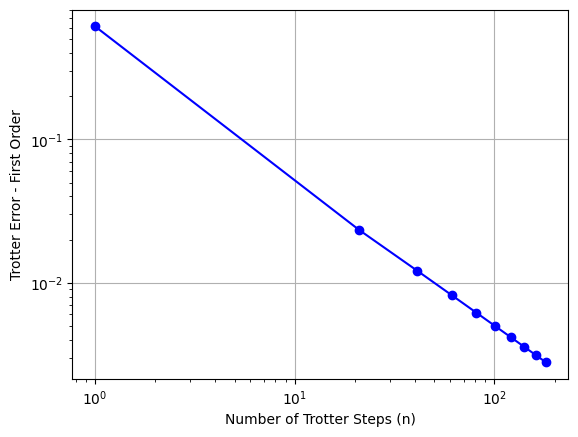

3


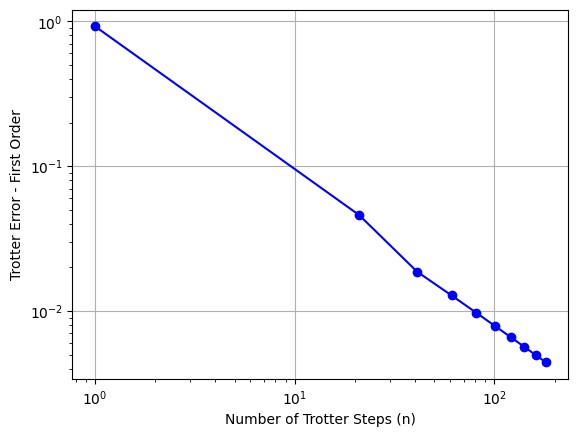

5


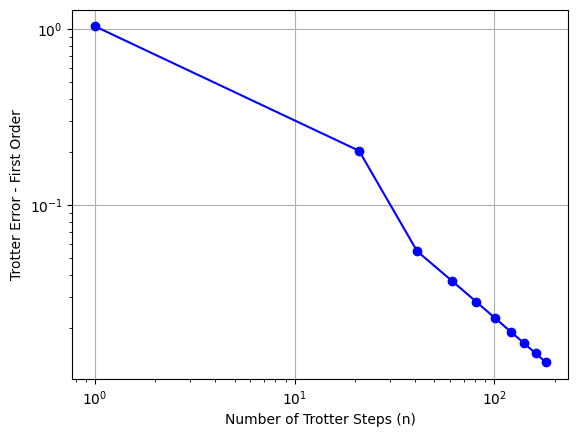

7


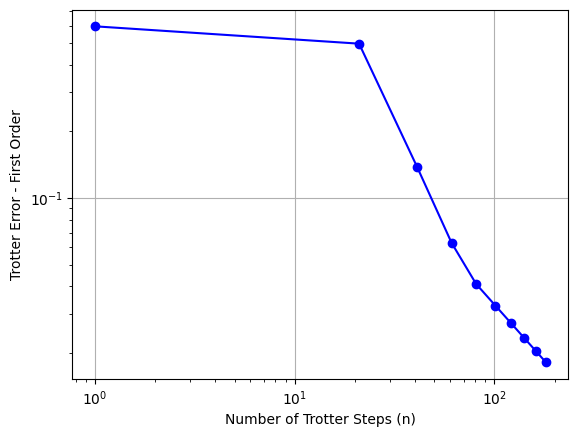

9


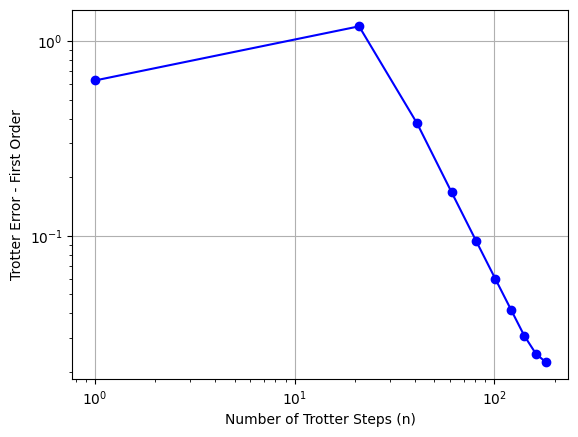

In [14]:


for t in range(1,10,2):
    print(t)
    trotter_errors_FO = []
    n_trotter_steps = list(range(1, 200, 20))

    qc_ising = get_ising_circ_FO(n,J,g,t,num_steps)
    approx_state = Statevector(qc_ising)
    true_ising_state = get_true_ising_state(n,J,g,t)
    curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
    trotter_errors_FO.append(curr_error)


    plt.plot(n_trotter_steps, trotter_errors_FO, marker='o', linestyle='-', color='b')
    plt.xlabel('Number of Trotter Steps (n)')
    plt.ylabel('Trotter Error - First Order')
    plt.xscale("log")
    plt.yscale("log")
    plt.grid(True)
    plt.show()

{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}
{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}


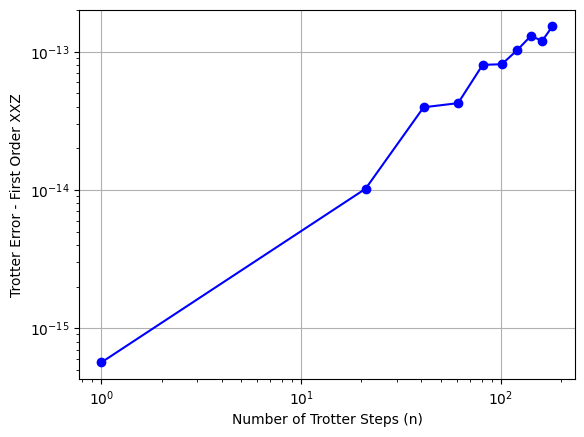

{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}


┌───┐                   ┌───┐┌────────────────┐                   »
q12_0: ┤ H ├──■─────────────■──┤ H ├┤ U(π/2,π/2,π/2) ├──■─────────────■──»
       ├───┤┌─┴─┐┌───────┐┌─┴─┐├───┤├────────────────┤┌─┴─┐┌───────┐┌─┴─┐»
q12_1: ┤ H ├┤ X ├┤ Rz(2) ├┤ X ├┤ H ├┤ U(π/2,π/2,π/2) ├┤ X ├┤ Rz(2) ├┤ X ├»
       ├───┤└───┘└───────┘└───┘└───┘└────────────────┘└───┘└───────┘└───┘»
q12_2: ┤ H ├─────────────────────────────────────────────────────────────»
       └───┘                                                             »
«       ┌────────────────┐                                                »
«q12_0: ┤ U(π/2,π/2,π/2) ├──■─────────────■───────────────────────────────»
«       ├────────────────┤┌─┴─┐┌───────┐┌─┴─┐┌───┐                   ┌───┐»
«q12_1: ┤ U(π/2,π/2,π/2) ├┤ X ├┤ Rz(1) ├┤ X ├┤ H ├──■─────────────■──┤ H ├»
«       └────────────────┘└───┘└───────┘└───┘└───┘┌─┴─┐┌───────┐┌─┴─┐├───┤»
«q12_2: ──────────────────────────────────────────┤ X ├┤ Rz(2) ├┤ X ├┤ H ├»
«                                                 └───┘└───────┘└───┘└───┘»
«                                                                            »
«q12_0: ─────────────────────────────────────────────────────────────────────»
«       ┌────────────────┐                   ┌────────────────┐              »
«q12_1: ┤ U(π/2,π/2,π/2) ├──■─────────────■──┤ U(π/2,π/2,π/2) ├──■───────────»
«       ├────────────────┤┌─┴─┐┌───────┐┌─┴─┐├────────────────┤┌─┴─┐┌───────┐»
«q12_2: ┤ U(π/2,π/2,π/2) ├┤ X ├┤ Rz(2) ├┤ X ├┤ U(π/2,π/2,π/2) ├┤ X ├┤ Rz(1) ├»
«       └────────────────┘└───┘└───────┘└───┘└────────────────┘└───┘└───────┘»
«            
«q12_0: ─────
«            
«q12_1: ──■──
«       ┌─┴─┐
«q12_2: ┤ X ├
«       └───┘

In [8]:
trotter_errors_FO = []
n_trotter_steps = list(range(1, 200, 20))
for num_steps in n_trotter_steps:
    
    qc_xxz = get_xxz_circ_FO(n,Delta_ZZ,t,num_steps)
    approx_state = Statevector(qc_xxz)

    curr_error = np.max(np.abs(approx_state - true_XXZ_state.vector))
    trotter_errors_FO.append(curr_error)


plt.plot(n_trotter_steps, trotter_errors_FO, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Trotter Steps (n)')
plt.ylabel('Trotter Error - First Order XXZ')
plt.xscale("log")
plt.yscale("log")
plt.grid(True)
plt.show()

circ= get_xxz_circ_FO(n,Delta_ZZ,t,1)
circ.draw()


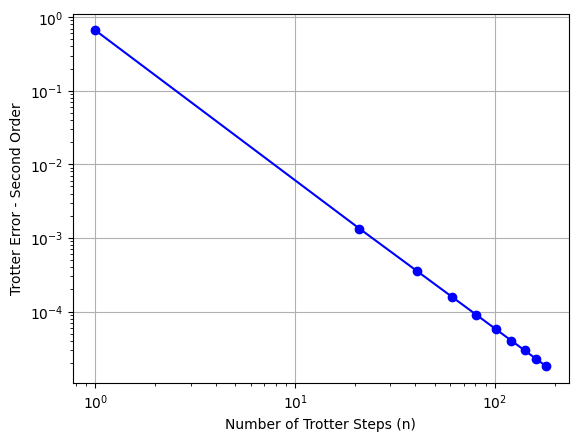

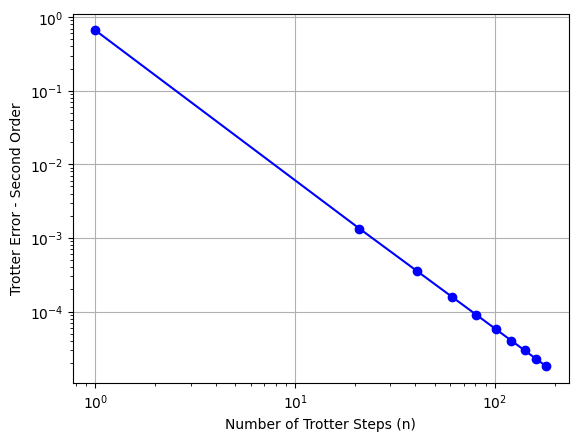

In [9]:
trotter_errors_SO = []
n_trotter_steps = list(range(1, 200, 20))
for num_steps in n_trotter_steps:
    qc_ising = get_ising_circ_SO(n,J,g,t,num_steps)
    approx_state = Statevector(qc_ising)

    curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
    # curr_error = np.linalg.norm(np.abs(approx_state - true_ising_state.vector))

    trotter_errors_SO.append(curr_error)


plt.plot(n_trotter_steps, trotter_errors_SO, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Trotter Steps (n)')
plt.ylabel('Trotter Error - Second Order')
plt.xscale("log")
plt.yscale("log")
plt.grid(True)
plt.show()

order = 2
trotter_errors_nth = []
n_trotter_steps = list(range(1, 200, 20))
for num_steps in n_trotter_steps:
    qc_ising = get_ising_circ_nth_order(n,J,g,t,num_steps,order)
    approx_state = Statevector(qc_ising)

    curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
    # curr_error = np.linalg.norm(np.abs(approx_state - true_ising_state.vector))

    trotter_errors_nth.append(curr_error)

plt.plot(n_trotter_steps, trotter_errors_nth, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Trotter Steps (n)')
plt.ylabel('Trotter Error - Second Order')
plt.xscale("log")
plt.yscale("log")
plt.grid(True)
plt.show()

In [82]:
import time
import numpy as np
from qiskit.quantum_info import Statevector

orders      = [1, 2, 4, 6, 8]
max_runtime = 5      # seconds
n_runs      = 5      # how many repeats to average

# containers for all orders:
Ns_all    = []
means_all = []
stds_all  = []

for order in orders:
    Ns    = []
    means = []
    stds  = []
    N = 1

    print(f"\n→ Processing order {order}-order")
    while True:
        # inner‐most loop: run the same (order,N) n_runs times
        runtimes = []
        for _ in range(n_runs):
            start = time.perf_counter()
            
            # build & simulate
            if order == 1:
                qc = get_ising_circ_FO(n, J, g, t, N)
            else:
                qc = get_ising_circ_nth_order(n, J, g, t, N, order)
            _ = Statevector(qc)
            
            runtimes.append(time.perf_counter() - start)
        
        mean = np.mean(runtimes)
        sd = np.std(runtimes)
        print(f"  N={N:3d} → mean={mean:.3f}s, std={sd:.3f}s")
        
        # stop as soon as the *mean* exceeds threshold
        if mean > max_runtime:
            break
        
        # record results
        Ns.append(N)
        means.append(mean)
        stds.append(sd)
        
        # increment N (you can tweak these schedules as you like)
        if   order == 1: N += 20
        elif order == 2: N += 10
        elif order == 4: N +=  3
        elif order == 6: N +=  2
        else:            N +=  1

    # stash per-order arrays
    Ns_all.append(np.array(Ns))
    means_all.append(np.array(means))
    stds_all.append(np.array(stds))

ts = datetime.now().strftime("%Y%m%d_%H%M%S")

# --- Save just the (N, mean, std) for each order into one .npz --- #
np.savez_compressed(
    f"trotter_runtime_results-{ts}.npz",
    orders = np.array(orders),
    Ns     = np.array(Ns_all,    dtype=object),
    means  = np.array(means_all, dtype=object),
    stds   = np.array(stds_all,  dtype=object),
    max_runtime=max_runtime,
    n_runs=n_runs
)

print("Saved summary to trotter_summary.npz")



→ Processing order 1-order
  N=  1 → mean=0.058s, std=0.087s
  N= 21 → mean=0.192s, std=0.087s
  N= 41 → mean=0.163s, std=0.063s
  N= 61 → mean=0.127s, std=0.016s
  N= 81 → mean=0.204s, std=0.028s
  N=101 → mean=0.221s, std=0.017s
  N=121 → mean=0.309s, std=0.144s
  N=141 → mean=0.371s, std=0.131s
  N=161 → mean=0.321s, std=0.009s
  N=181 → mean=0.509s, std=0.174s
  N=201 → mean=0.511s, std=0.115s
  N=221 → mean=0.568s, std=0.169s
  N=241 → mean=0.758s, std=0.333s
  N=261 → mean=0.633s, std=0.122s
  N=281 → mean=0.623s, std=0.065s
  N=301 → mean=0.666s, std=0.031s
  N=321 → mean=0.943s, std=0.222s
  N=341 → mean=0.872s, std=0.127s
  N=361 → mean=1.015s, std=0.156s
  N=381 → mean=0.929s, std=0.048s
  N=401 → mean=1.083s, std=0.213s
  N=421 → mean=1.043s, std=0.030s
  N=441 → mean=1.348s, std=0.171s
  N=461 → mean=1.196s, std=0.028s
  N=481 → mean=1.284s, std=0.130s
  N=501 → mean=1.299s, std=0.039s
  N=521 → mean=1.434s, std=0.096s
  N=541 → mean=1.562s, std=0.164s
  N=561 → mean=1.612

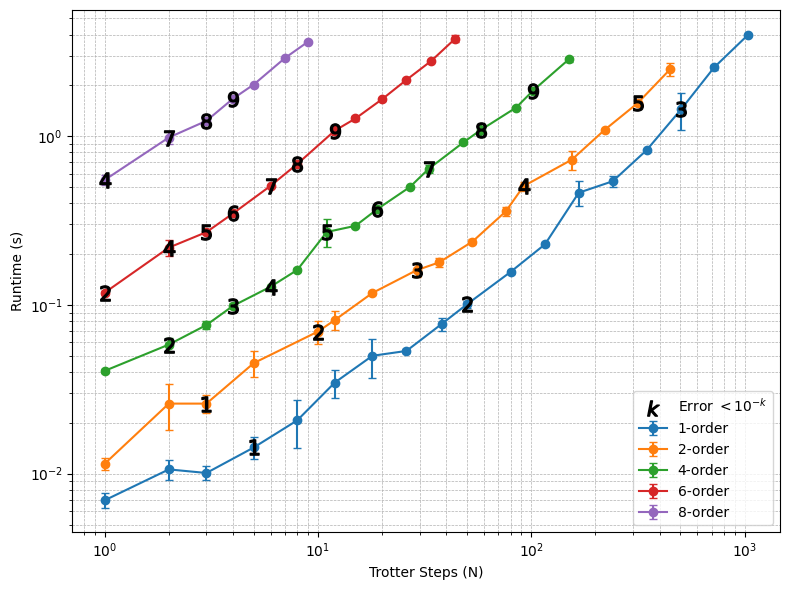

In [129]:
import numpy as np
import matplotlib.pyplot as plt

crossings = {
    1: {1:5,    2:50,   3:504,  4:5043          },
    2: {1:3,    2:10,   3:29,   4:92,   5:315  },
    4: {1:2,    2:2,    3:4,    4:6,    5:11,
        6:19,   7:33,   8:58,   9:102         },
    6: {1:1,    2:1,    3:2,    4:2,    5:3,
        6:4,    7:6,    8:8,    9:12          },
    8: {1:1,    2:1,    3:1,    4:1,    5:2,
        6:2,    7:2,    8:3,    9:4           }
}
Ns_list = [
    [1, 2, 3, 5, 8, 12, 18, 26, 38, 50, 80, 116, 167, 241, 347, 504, 720, 1036],
    [1, 2, 3, 5, 10, 12, 18, 29, 37, 53, 76, 92, 155, 221, 315, 448],
    [1, 2, 3, 4, 6, 8, 11, 15, 19, 27, 33, 48, 58, 85, 102, 150],
    [1, 2, 3, 4, 6, 8, 12, 15, 20, 26, 34, 44],
    [1, 2, 3, 4, 5, 7, 9]
]


# --- Load your summary data ---
data    = np.load("trotter_runtime_results-20250430_200129.npz", allow_pickle=True)
orders  = data["orders"]  # e.g. array([1,2,4,6,8])
Ns_all  = data["Ns"]      # object-array: one list of Ns per order
means   = data["means"]   # object-array: one array of mean runtimes per order
stds    = data["stds"]    # object-array: one array of stddev per order
markers = {
1:([5,3],[means[0][3],means[1][2]]),
2:([50,10,2,1],[means[0][9],means[1][4],means[2][1],means[3][0]]),
3:([504,29,4],[means[0][15],means[1][7],means[2][3]]),
4:([92,6,2,1],[means[1][11],means[2][4],means[3][1],means[4][0]]),
5:([315,11,3],[means[1][14],means[2][6],means[3][2]]),
6:([19,4],[means[2][8],means[3][3]]),
7:([33,6,2],[means[2][10],means[3][4],means[4][1]]),
8:([58,8,3],[means[2][12],means[3][5],means[4][2]]),
9:([102,12,4],[means[2][14],means[3][6],means[4][3]]),
}


# --- Plot ---
plt.figure(figsize=(8,6))

for order, Ns, mean, sd in zip(orders, Ns_all, means, stds):
    plt.errorbar(
        Ns, mean, yerr=sd,
        marker='o', linestyle='-',
        capsize=3,
        label=f'{order}-order'
    )

for k, (xs, ys) in markers.items():
    plt.scatter(
        xs, ys,
        marker=f'${k}$',   # puts the digit “k” as the marker
        s=120,             # marker size
        c='black',         # color
        zorder=5,
    )
plt.scatter([], [],
            marker=r'$k$',
            c='black',
            s=120,
            label='Error $<10^{-k}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Trotter Steps (N)')
plt.ylabel('Runtime (s)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('trotter_runtime_plot')
plt.show()


In [ ]:
# your parameters
n_trotter_steps = [1,2,4,6,8,10,20,30,40,50,60,80,100]
orders = [1,2,4,6,8]
n_runs = 1

# allocate: shape (n_runs, n_orders, n_steps)
all_errors = np.zeros((n_runs, len(orders), len(n_trotter_steps)))

for run in range(n_runs):
    print(f"\n=== RUN {run+1}/{n_runs} ===")
    for i_order, order in enumerate(orders):
        print(f' Order {order}-order')
        for i_step, num_steps in enumerate(n_trotter_steps):
            print(f'   N = {num_steps}')
            # build circuit & get state
            if order == 1:
                qc = get_ising_circ_FO(n, J, g, t, num_steps)
            else:
                qc = get_ising_circ_nth_order(n, J, g, t, num_steps, order)
            approx = Statevector(qc)
            # compute error
            err = np.max(np.abs(approx.vector - true_ising_state.vector))
            all_errors[run, i_order, i_step] = err

# compute statistics across runs
mean_err = all_errors.mean(axis=0)   # shape (n_orders, n_steps)
std_err  = all_errors.std(axis=0)    # shape (n_orders, n_steps)
np.save(f"trotter_errors-{ts}.npy", trotter_errors_arr)


<>:35: SyntaxWarning: invalid escape sequence '\e'
<>:35: SyntaxWarning: invalid escape sequence '\e'
/var/folders/q5/txpbw5mx6cv59tk97zgkc3v00000gn/T/ipykernel_58835/752299993.py:35: SyntaxWarning: invalid escape sequence '\e'
  plt.ylabel('Trotter Error $\epsilon(N)$')


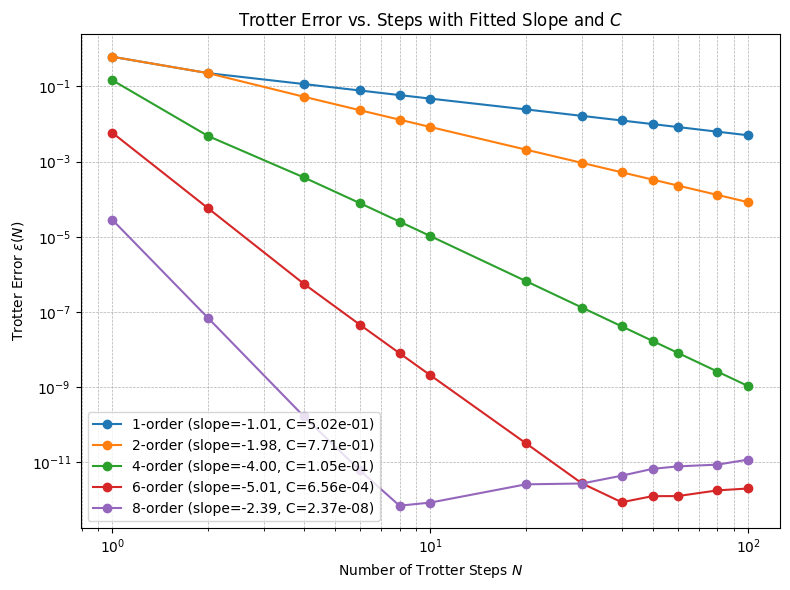

In [263]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Load your saved errors array
trotter_errors = np.load("trotter_errors-20250430_133702.npy")

# Define Trotter step counts and orders
n_trotter_steps = np.array([1, 2, 4, 6, 8, 10, 20, 30, 40, 50, 60, 80, 100])
orders = [1, 2, 4, 6, 8]

# Reference time for intercept extraction
t0 = 1.0

plt.figure(figsize=(8, 6))
for i, order in enumerate(orders):
    errs = trotter_errors[i]
    
    # Fit in log-log space
    logN = np.log(n_trotter_steps)
    logE = np.log(errs)
    slope, intercept = np.polyfit(logN, logE, 1)
    
    # Estimate C from intercept: intercept = log(C * t0^(r+1))
    C_est = np.exp(intercept) / (t0 ** (order + 1))
    
    # Plot with slope and C in the legend
    label = f"{order}-order (slope={slope:.2f}, C={C_est:.2e})"
    plt.plot(n_trotter_steps, errs, marker='o', linestyle='-', label=label)

# Styling
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Number of Trotter Steps $N$')
plt.ylabel('Trotter Error $\epsilon(N)$')
plt.title('Trotter Error vs. Steps with Fitted Slope and $C$')
plt.grid(True, which='both', ls='--', lw=0.5)
plt.legend()
plt.tight_layout()

# Optional: save figure with timestamp
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'trotter_error_fit_{ts}.png', dpi=300)

plt.show()


In [ ]:
orders = [1,2,4,6,8]
n_runs = 3

# allocate: shape (n_runs, n_orders, n_steps)
all_runtimes = np.zeros((n_runs, len(orders), len(n_trotter_steps)))

for run in range(n_runs):
    print(f"\n=== RUN {run+1}/{n_runs} ===")
    for i_order, order in enumerate(orders):
        print(f' Order {order}-order')
        for i_step, num_steps in enumerate(n_trotter_steps):
            print(f'   N = {num_steps}')
            # build circuit & get state
            if order == 1:
                qc = get_ising_circ_FO(n, J, g, t, num_steps)
            else:
                qc = get_ising_circ_nth_order(n, J, g, t, num_steps, order)
            approx_state = Statevector(qc)
            # compute error
            err = np.max(np.abs(approx_state - true_ising_state.vector))
            all_errors[run, i_order, i_step] = err
all_errors_arr = np.array(all_errors)
ts = datetime.now().strftime("%Y%m%d_%H%M%S")  

In [9]:
def measure_pauli_expectation(qc, n,pauli_string, shots= 1024) -> float:
    """
    Given a QuantumCircuit qc and a Pauli observable specified by a string (one char per qubit),
    return the expectation value of the Pauli observable.
    
    Parameters:
        qc: The input quantum circuit (without measurement).
        pauli_string (str): A string of length equal to n.
                            Each character should be 'X', 'Y', 'Z', or 'I', representing the Pauli operator
                            on the corresponding qubits.
    
    Returns:
        float: The expectation value of the observable.
    """
    
    # Create a copy of the circuit so we don't alter the original.
    qc_meas = qc.copy()

    # Perform the basis-change rotations so that a Z-measurement yields the eigenvalue of the desired Pauli.
    # Note: Qiskit uses the convention that qubit 0 corresponds to the rightmost bit in measurement outcomes.
    for i, pauli in enumerate(pauli_string):
        p = pauli.upper()
        if p == 'X':
            qc_meas.h(i)
        elif p == 'Y':
            qc_meas.sdg(i)
            qc_meas.h(i)
        
    
    # Add a classical register and measure all qubits.
    cr = ClassicalRegister(n)
    qc_meas.add_register(cr)
    qc_meas.measure(range(n), cr)
    
    # Use provided backend or default to the Aer qasm_simulator.
   
    result = AerSimulator().run(qc_meas).result()
    counts = result.get_counts()
    # print(counts)

    # Compute the expectation value:
    # For each shot, multiply the eigenvalue contributions from each qubit that is measured in a non-identity basis.
    # In the computational basis, '0' corresponds to +1 and '1' corresponds to -1.
    expectation = 0
    for bitstring, cnt in counts.items():
        # Qiskit orders the bits so that the rightmost bit is from qubit 0.
        shot_val = 1
        # Reverse the bit string so index 0 corresponds to qubit 0.
        for i, bit in enumerate(bitstring[::-1]):
            if pauli_string[i].upper() in ['X', 'Y', 'Z']:
                eigenvalue = 1 if bit == '0' else -1
                shot_val *= eigenvalue
            # If the operator is identity, ignore that qubit.
        expectation += shot_val * cnt

    # Normalize by the number of shots to get the average.
    expectation /= shots
    return expectation

    

In [ ]:

Ns = []
times = np.linspace(0.0, 5.0, 100) 
observable = 'Z'*n
print(f'<{observable}>')
expectations = []
gs = [1,3,5]
for i in range(len(gs)):
    expectations_g = []
    for t in times:
        qc = get_ising_circ_SO(n,J=1,g=gs[i],t=t,N=N)
        expectation = measure_pauli_expectation(qc,n,observable)
        expectations_g.append(expectation)
    expectations.append(expectations_g)

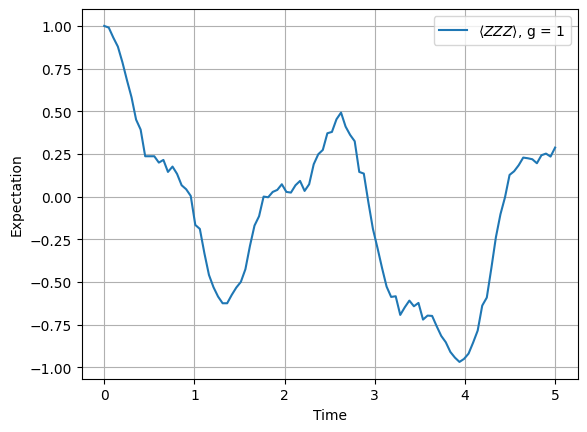

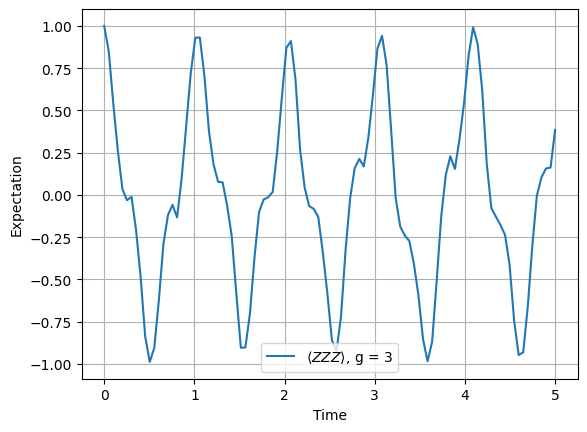

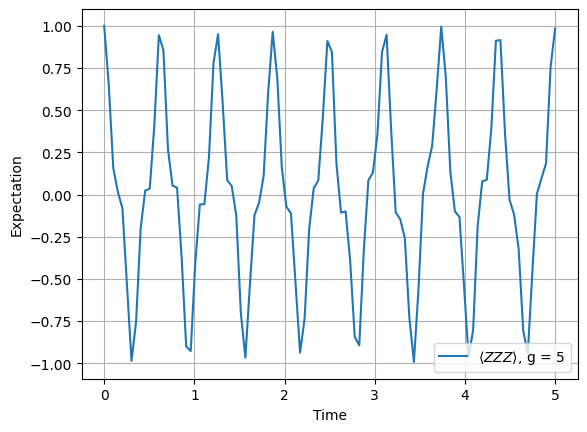

In [12]:
for i in range(len(gs)):
    plt.figure()  # Create a new figure window
    plt.plot(times, expectations[i], linestyle='-', 
             label=fr'$\langle {observable} \rangle$, g = {gs[i]}')
    plt.xlabel("Time")
    plt.ylabel("Expectation")
    plt.grid(True)
    plt.legend()
    plt.show()   #

In [323]:
  # 4: {1:2,    2:2,    3:4,    4:6,    5:11,
  #       6:19,   7:33,   8:58,   9:102         },
n = 5
J = 1
g = 1.2
Energies = []
r=2
Ns = [20,30,40,50]
times = np.linspace(0.0, 20, 50) 
ham_ising = get_transverse_Ising_hamiltonian_dict(n, g, J)

for N in Ns:
    print(f'N: {N}')
    Energies_N = []
    for t in times:
        print(t)
        Energy = 0
        qc = get_ising_circ_nth_order(n, J, g, t, N, r)
        for pauli_string in ham_ising:
            weight = ham_ising[pauli_string]
            Energy += weight * measure_pauli_expectation(qc, n, pauli_string)
        Energies_N.append(Energy)
    Energies.append(Energies_N)

# ts = datetime.now().strftime("%Y%m%d_%H%M%S")  

# np.save(f'energies{ts}.npy', Energies)



  
  

N: 20
0.0


0.40816326530612246
0.8163265306122449
1.2244897959183674
1.6326530612244898
2.0408163265306123
2.4489795918367347
2.857142857142857
3.2653061224489797
3.673469387755102
4.081632653061225
4.4897959183673475
4.8979591836734695
5.3061224489795915
5.714285714285714
6.122448979591837
6.530612244897959
6.938775510204081
7.346938775510204
7.755102040816327
8.16326530612245
8.571428571428571
8.979591836734695
9.387755102040817
9.795918367346939
10.204081632653061
10.612244897959183
11.020408163265307
11.428571428571429
11.83673469387755
12.244897959183675
12.653061224489797
13.061224489795919
13.46938775510204
13.877551020408163
14.285714285714286
14.693877551020408
15.10204081632653
15.510204081632654
15.918367346938776
16.3265306122449
16.73469387755102
17.142857142857142
17.551020408163264
17.95918367346939
18.367346938775512
18.775510204081634
19.183673469387756
19.591836734693878
20.0
N: 30
0.0
0.40816326530612246
0.8163265306122449
1.2244897959183674
1.6326530612244898
2.040816326530612

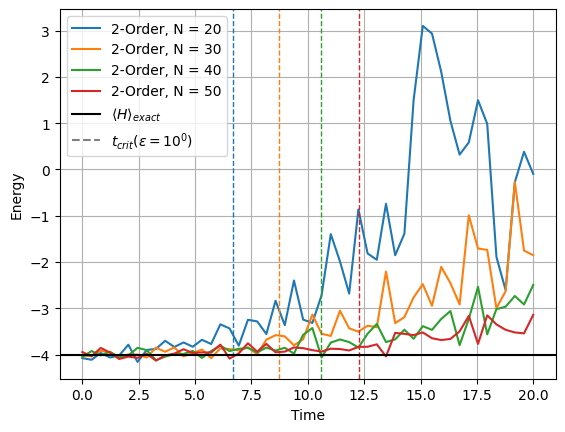

In [329]:
C = 1.350
delta = 1
# r = 2
# Ns = [1,3,6,9,12]

plt.figure()
for i in range(len(Ns)):
    # compute t_crit
    tcrit = (delta * (Ns[i]**r) / C)**(1/(r+1))
    
    # plot the solid curve and capture its Line2D handle
    line, = plt.plot(
        times,
        Energies[i],
        linestyle='-',
        label=f'{r}-Order, N = {Ns[i]}'
    )
    # extract its color
    col = line.get_color()
    
    # draw the vertical dashed line with the same color
    plt.axvline(
        x=tcrit,
        linestyle='--',
        color=col,
        linewidth=1,
        # label = r"$t_{critical}$"
    )
plt.axhline(y=-4, linestyle='-', color='black', label=r"$\langle H \rangle_{exact}$")
plt.plot([],[],linestyle='--', color='gray', label = r'$t_{crit}(\epsilon = 10^{0})$')
plt.xlabel("Time")

plt.ylabel("Energy")
plt.grid(True)
plt.legend()
plt.savefig("Final_Energies_1")
plt.show()   

In [44]:

order_N = [(2,92),(4,6),(6,2),(8,1)]
times = np.linspace(0.2, 10.0, 50) 
trotter_errors = []
for (order,N) in order_N:   
    print(f'Order: {order}') 
    trotter_errors_order = []
    for t in times:
        print(t)
        qc_ising = get_ising_circ_nth_order(n,J,g,t,N,order)
        approx_state = Statevector(qc_ising)
        true_ising_state = get_true_ising_state(n,J,g,t)
        curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
        trotter_errors_order.append(curr_error)
    trotter_errors.append(trotter_errors_order) 


Order: 2
0.2
0.4
0.6000000000000001
0.8
1.0
1.2
1.4000000000000001
1.6
1.8
2.0
2.2
2.4000000000000004
2.6000000000000005
2.8000000000000003
3.0000000000000004
3.2
3.4000000000000004
3.6000000000000005
3.8000000000000003
4.0
4.2
4.4
4.6000000000000005
4.800000000000001
5.000000000000001
5.2
5.4
5.6000000000000005
5.800000000000001
6.000000000000001
6.2
6.4
6.6000000000000005
6.800000000000001
7.000000000000001
7.2
7.4
7.6000000000000005
7.800000000000001
8.0
8.2
8.4
8.6
8.799999999999999
9.0
9.2
9.4
9.6
9.8
10.0
Order: 4
0.2
0.4
0.6000000000000001
0.8
1.0
1.2
1.4000000000000001
1.6
1.8
2.0
2.2
2.4000000000000004
2.6000000000000005
2.8000000000000003
3.0000000000000004
3.2
3.4000000000000004
3.6000000000000005
3.8000000000000003
4.0
4.2
4.4
4.6000000000000005
4.800000000000001
5.000000000000001
5.2
5.4
5.6000000000000005
5.800000000000001
6.000000000000001
6.2
6.4
6.6000000000000005
6.800000000000001
7.000000000000001
7.2
7.4
7.6000000000000005
7.800000000000001
8.0
8.2
8.4
8.6
8.7999999

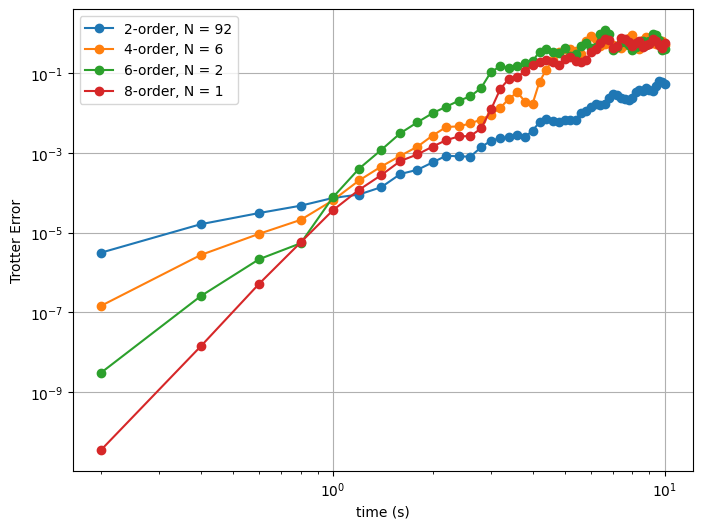

In [47]:
plt.figure(figsize=(8,6))
for i in range(len(order_N)):
    order = order_N[i][0]
    N = order_N[i][1]
    plt.plot(times, trotter_errors[i], marker='o', linestyle='-', label = f"{order}-order, N = {N}")
    # plt.plot(times, times**(order+1)/N**order, linestyle='--' , label = f"{order}-order, N = {N} theoretical")
plt.xlabel('time (s)')
plt.ylabel('Trotter Error')
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

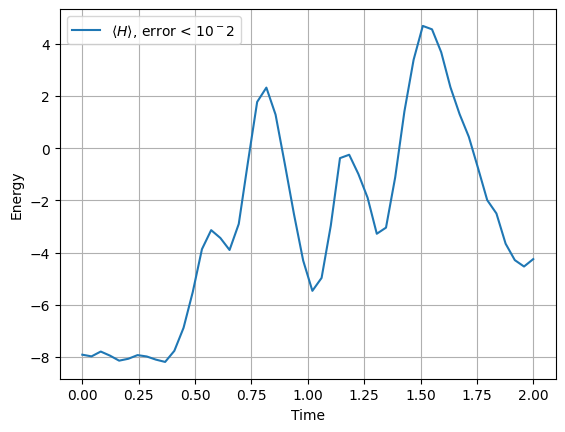

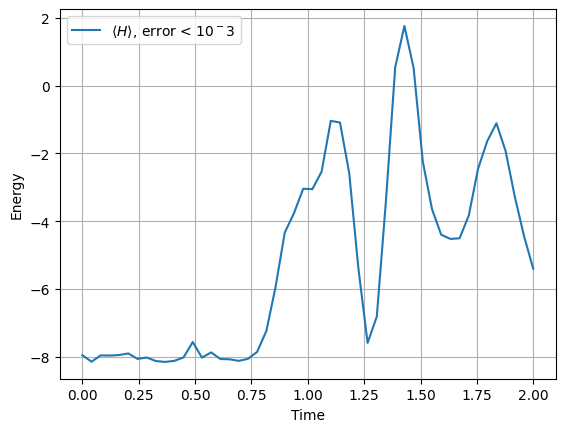

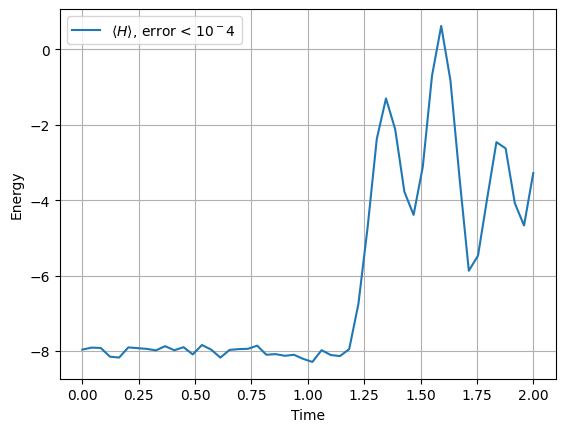

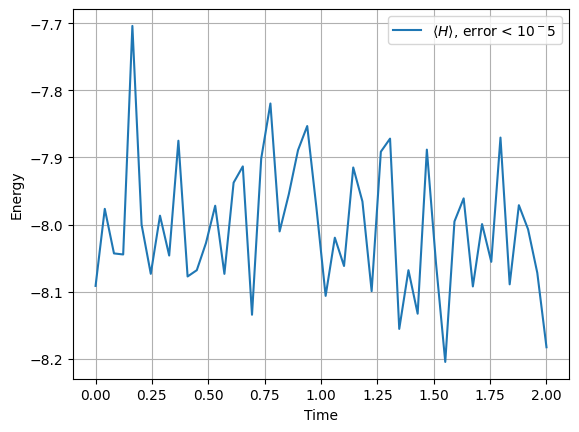

In [30]:

for i in range(len(Ns)):
    plt.figure()  # Create a new figure window
    plt.plot(times, Energies[i], linestyle='-', 
             label=fr'$\langle H \rangle$, error < $10^-{i+2}$')
    plt.xlabel("Time")
    plt.ylabel("Energy")
    plt
    plt.grid(True)
    plt.legend()
    plt.show()   #

In [319]:
r = 2
# E_tol = 1e-6          # use 1e-2, not 10^-2
Ns    = np.arange(1,500,20)
C = 1.35

# the true formula is t_crit = (E_tol * N^r)^(1/(r+1))
times = []
trotter_errors = []
t_crit_over_N_all = []
for i in range(1,6):
    E_tol = 10**(-i)
    times_tol = (E_tol/C * Ns**r)**(1/(r+1))
    times.append(times_tol)
    trotter_errors_tol = []
    t_crit_over_N_tol = []
    for N, t in zip(Ns, times_tol):
        print(N)
        t_crit_over_N = t/N
        t_crit_over_N_tol.append(t_crit_over_N)
        qc_ising     = get_ising_circ_nth_order(n, J, g, t, N, r)
        approx_state = Statevector(qc_ising)
        true_state   = get_true_ising_state(n, J, g, t)
        # make sure to subtract the .vector attribute
        curr_error   = np.linalg.norm(approx_state - true_state.vector)
        # curr_error   = np.max(np.abs(approx_state - true_state.vector))

        trotter_errors_tol.append(curr_error)
    trotter_errors.append(trotter_errors_tol)
    t_crit_over_N_all.append(t_crit_over_N_tol)


1
21
41
61
81
101
121
141
161
181
201
221
241
261
281
301
321
341
361
381
401
421
441
461
481
1
21
41
61
81
101
121
141
161
181
201
221
241
261
281
301
321
341
361
381
401
421
441
461
481
1
21
41
61
81
101
121
141
161
181
201
221
241
261
281
301
321
341
361
381
401
421
441
461
481
1
21
41
61
81
101
121
141
161
181
201
221
241
261
281
301
321
341
361
381
401
421
441
461
481
1
21
41
61
81
101
121
141
161
181
201
221
241
261
281
301
321
341
361
381
401
421
441
461
481


N = [  1  21  41  61  81 101 121 141 161 181 201 221 241 261 281 301 321 341
 361 381 401 421 441 461 481]
C=1.35
r = 2


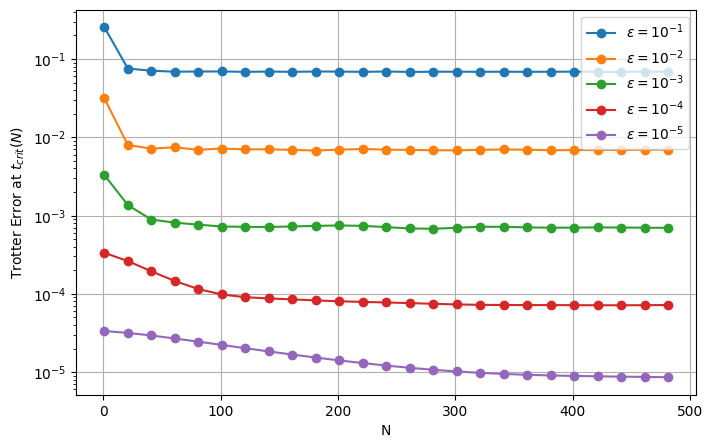

In [321]:
print(f"N = {Ns}")
print(f'C={C}')
print(f"r = {r}")
plt.figure(figsize=(8,5))
for i in range(len(trotter_errors)):

  plt.plot(Ns, trotter_errors[i], marker='o', linestyle='-', label = fr'$\epsilon = 10^{{-{i+1}}}$')
  
plt.xlabel('N')
plt.ylabel(fr'Trotter Error at $t_{{crit}}(N)$')
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.savefig("Final_Trotter_error_at_t_crit")
plt.show()

# plt.figure(figsize=(8,5))
# for i in range(len(trotter_errors)):

#   plt.plot(times[i], t_crit_over_N_all[i], marker='o', linestyle='-')
  
# plt.xlabel('t_crit(N)')
# plt.ylabel('t/N')
# plt.yscale("log")
# plt.grid(True)



In [309]:
N=300
C= 1.35
r =2
eps = np.array([-1,-2,-3,-4,-5])
t_crit = (10.0**(eps)/C*N**r)**(1/(r+1))
order_N = [(r,N)]
# times = np.linspace(0.2, 20, 20)
times = np.logspace(np.log10(0.2), np.log10(20), 20)

trotter_errors = []
for (order,N) in order_N:   
  print(f'Order: {order}') 
  trotter_errors_order = []
  for t in times:
      print(t)
      qc_ising = get_ising_circ_nth_order(n,J,g,t,N,order)
      approx_state = Statevector(qc_ising)
      true_ising_state = get_true_ising_state(n,J,g,t)
      curr_error = np.max(np.abs(approx_state - true_ising_state.vector))
      trotter_errors_order.append(curr_error)
  trotter_errors.append(trotter_errors_order) 


Order: 2
0.20000000000000004
0.25485499714062676
0.3247553478377444
0.413827616222958
0.5273301797460717
0.6719636572567564
0.8562664797438788
1.0911189562337038
1.3903855923551212
1.7717335808201653
2.257675783369378
2.876899776575326
3.6659614216648717
4.671442938180244
5.952702883262636
7.585380381464501
9.665860477143505
12.316964221320523
15.695199407029223
20.000000000000004


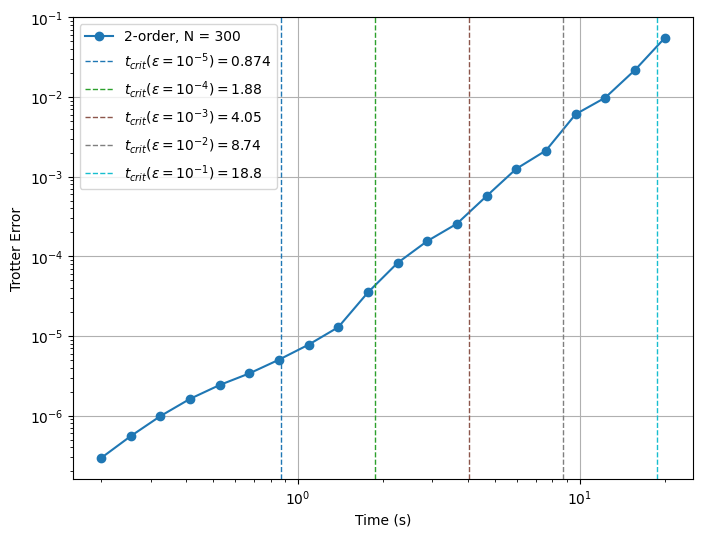

In [317]:
plt.figure(figsize=(8,6))
eps = np.array([-5,-4,-3,-2,-1])
t_crit = (10.0**(eps)/C*N**r)**(1/(r+1))
for i in range(len(order_N)):
    order = order_N[i][0]
    N = order_N[i][1]
    plt.plot(times, trotter_errors[i], marker='o', linestyle='-', label = f"{order}-order, N = {N}")
    colors = plt.cm.tab10(np.linspace(0, 1, len(t_crit)))

# Plot vertical lines, each with its own color
    for i, t in enumerate(t_crit):
        plt.axvline(
            x=t,
            color=colors[i],
            linestyle='--',
            linewidth=1,
            label=fr"$t_{{crit}}(\epsilon = 10^{{{eps[i]}}}) = {t:.3g}$"
        )
    # plt.plot(times, times**(order+1)/N**order, linestyle='--' , label = f"{order}-order, N = {N} theoretical")
plt.xlabel('Time (s)')
plt.ylabel('Trotter Error')
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.savefig("Final_trotter_error_vs_time")
plt.show()

In [275]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector

# --- Parameters ---
n = 5           # number of spins
J, g = 1.0, 1.2
t0 = 1    
orders = [1, 2, 4, 6, 8]

# Containers
Errors_all = []
Cs_est = []
slopes = []
# Define Ns for each order
Ns = np.array([1, 2, 3, 4, 5, 6, 7, 8, 10, 20, 30, 40, 50, 60, 80, 100])

# Loop over orders
for r in orders:
    errors = []
    print(f"Order: {r}")
    for N in Ns:
        print(f"N: {N}")
        qc_trot = get_ising_circ_nth_order(n, J, g, t0, N, r)
        approx_state = Statevector(qc_trot)
        true_state = get_true_ising_state(n, J, g, t0)
        eps = np.linalg.norm(approx_state - true_state.vector)
        errors.append(eps)
    errors = np.array(errors)
    Errors_all.append(errors)
    
  


# Save data
np.savez("trotter_errors_filtered.npz", Ns=Ns, Errors_all=Errors_all, orders=orders)


Order: 1
N: 1
N: 2


N: 3
N: 4
N: 5
N: 6
N: 7
N: 8
N: 10
N: 20
N: 30
N: 40
N: 50
N: 60
N: 80
N: 100
Order: 2
N: 1
N: 2
N: 3
N: 4
N: 5
N: 6
N: 7
N: 8
N: 10
N: 20
N: 30
N: 40
N: 50
N: 60
N: 80
N: 100
Order: 4
N: 1
N: 2
N: 3
N: 4
N: 5
N: 6
N: 7
N: 8
N: 10
N: 20
N: 30
N: 40
N: 50
N: 60
N: 80
N: 100
Order: 6
N: 1
N: 2
N: 3
N: 4
N: 5
N: 6
N: 7
N: 8
N: 10
N: 20
N: 30
N: 40
N: 50
N: 60
N: 80
N: 100
Order: 8
N: 1
N: 2
N: 3
N: 4
N: 5
N: 6
N: 7
N: 8
N: 10
N: 20
N: 30
N: 40
N: 50
N: 60
N: 80
N: 100


[1.5976244855705624, 0.6463310576331402, 0.42502191939585243, 0.3201415607402733, 0.257688342036178, 0.21592056868974455, 0.1859219067748106, 0.16329598997541026, 0.13139092519042128, 0.0665625629568964, 0.044589549898925517, 0.0335256170998862, 0.026861318228068365, 0.022407377224057785, 0.016827267209163523, 0.013472341161146761]
[1.5976244855705624, 0.6463310576331402, 0.42502191939585243, 0.3201415607402733, 0.257688342036178, 0.21592056868974455, 0.1859219067748106, 0.16329598997541026, 0.13139092519042128, 0.0665625629568964, 0.044589549898925517, 0.0335256170998862, 0.026861318228068365, 0.022407377224057785, 0.016827267209163523, 0.013472341161146761]
[  1   2   3   4   5   6   7   8  10  20  30  40  50  60  80 100]
[1.4223053942679555, 0.35271248293075425, 0.1460341800368073, 0.08004160500194268, 0.050610376098899755, 0.03491510347994283, 0.025549981104710382, 0.01951117918870455, 0.01244921120109267, 0.0030996909741923184, 0.001376604464371619, 0.0007741361405967381, 0.000495

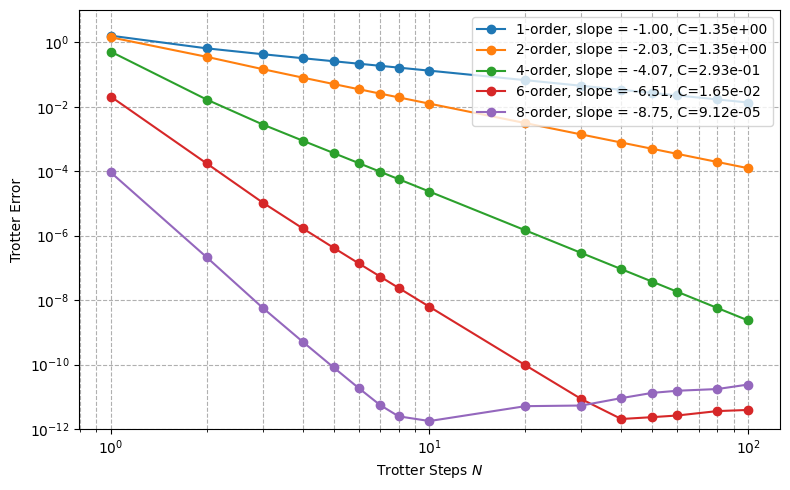

In [292]:
Cs_est = []
slopes = []

data = np.load("trotter_errors_filtered.npz", allow_pickle=True)

# Extract the arrays
Ns          = data["Ns"]            # 1D array of N values
Errors_all  = data["Errors_all"]    # list/array of error‐arrays
orders      = data["orders"]        # list of Trotter orders

# If Errors_all was saved as a list of numpy arrays, you may need to do:
Errors_all = Errors_all.tolist()    # convert back to a Python list of arrays


for i,order in enumerate(orders):
    errors_fit = []
    for e in Errors_all[i]:
        if e > 1e-10:
            errors_fit.append(e)
    
    print(Errors_all[i])
    num_filtered = len(errors_fit)
    Ns_fit = Ns[:num_filtered]
    print(errors_fit)
    print(Ns_fit)
        # 3) Fit only if enough points

    logN = np.log(Ns_fit)
    logE = np.log(errors_fit)
    m, b = np.polyfit(logN, logE, 1)
   

    slopes.append(m)
    # Recover C: intercept = log(C * t0^(r+1))
    C_est = np.exp(b) / (t0**(r+1)) if not np.isnan(b) else np.nan
    Cs_est.append(C_est)



plt.figure(figsize=(8, 5))
for i, r in enumerate(orders):
    errs = Errors_all[i]
    plt.loglog(Ns, errs, marker='o', linestyle='-',
               label=fr'{r}-order, slope = {slopes[i]:.2f}, C={Cs_est[i]:.2e}')

plt.xlabel('Trotter Steps $N$')
plt.ylabel(r'Trotter Error')
plt.ylim(1e-12,1e1)               # y-axis from 10^0 down to 10^-12
plt.legend(loc='upper right')     # place legend in the top-right corner
plt.grid(True, which='both', ls='--')
plt.tight_layout()
plt.savefig('Final_error_vs_N')
plt.show()


50
55
60
65
70
75
80
85
90
95
100
105
110
115
120
125
130
135
140
145
Fitted slope = 0.737  (should ≃ -2)
Fitted intercept = -6.467
Estimated C_E ≈ 1.554e+06


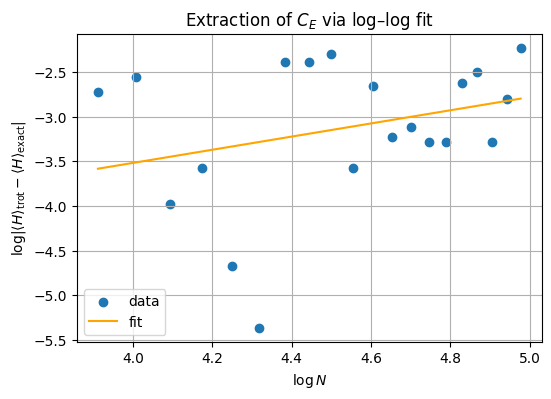

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector

# --- user parameters ---
n     = 5               # number of spins
J, g  = 1.0, 1.2        # Ising couplings
r     = 2               # Trotter order
t0    = 0.001           # reference time
E_tol = 1.0             # if you ever need it
Ns    = np.arange(50, 150, 5)        # list of N values to test
ham_ising = get_transverse_Ising_hamiltonian_dict(n, g, J)
# ------------------------

# first get the exact energy once at t0
E_exact = get_true_ising_energy(n, J, g, t0)

# collect the energy errors
energy_errors = []
for N in Ns:
    print(N)
    # build & simulate the Trotter circuit at t0
    qc_trot = get_ising_circ_nth_order(n, J, g, t0, N, r)
    
    # measure <H>_trot via the Pauli‐string expansion
    E_trot = 0.0
    for pauli_string, weight in ham_ising.items():
        E_trot += weight * measure_pauli_expectation(qc_trot, n, pauli_string)
    
    # absolute energy error
    energy_errors.append(abs(E_trot - E_exact))

# now fit log–log: log(eps_E) = -r log(N) + b  with  b = log(C_E * t0^(r+1))
logN = np.log(Ns)
logE = np.log(energy_errors)
slope, intercept = np.polyfit(logN, logE, 1)

print(f"Fitted slope = {slope:.3f}  (should ≃ -{r})")
print(f"Fitted intercept = {intercept:.3f}")

# recover C_E:
C_E = np.exp(intercept) / (t0**(r+1))
print(f"Estimated C_E ≈ {C_E:.3e}")

# optional: plot the data and fit
plt.figure(figsize=(6,4))
plt.scatter(logN, logE, label="data")
plt.plot(logN, slope*logN + intercept, color='orange', label="fit")
plt.xlabel(r"$\log N$")
plt.ylabel(r"$\log|\langle H\rangle_{\rm trot}-\langle H\rangle_{\rm exact}|$")
plt.title("Extraction of $C_E$ via log–log fit")
plt.legend()
plt.grid(True)
plt.show()


In [283]:
from qiskit import transpile

def count_cnots(qc):
    # Ensure the circuit is expressed in u1,u2,u3,cx basis
    bc = transpile(qc, basis_gates=["u1","u2","u3","cx"], optimization_level=0)
    ops = bc.count_ops()
    return ops.get("cx", 0)

# Your lists of N and orders
Ns_list = [
    [  1,   2,   3,   5,   8,  12,  18,  26,  38,  50,  80, 116, 167, 241, 347, 504, 720,1036],
    [  1,   2,   3,   5,  10,  12,  18,  29,  37,  53,  76,  92, 155, 221, 315, 448],
    [  1,   2,   3,   4,   6,   8,  11,  15,  19,  27,  33,  48,  58,  85, 102, 150],
    [  1,   2,   3,   4,   6,   8,  12,  15,  20,  26,  34,  44],
    [  1,   2,   3,   4,   5,   7,   9]
]
orders = [1, 2, 4, 6, 8]

cx_count_all = []

for order, Ns in zip(orders, Ns_list):
    cx_counts = []
    print(f"\n→ Processing {order}‑order Trotter")
    for N in Ns:
        # Build the Trotter circuit
        if order == 1:
            qc = get_ising_circ_FO(n, J, g, t, N)
        else:
            qc = get_ising_circ_nth_order(n, J, g, t, N, order)

        # Count CX gates
        cx_ct = count_cnots(qc)
        print(f"  N={N:4d} → CX count = {cx_ct}")
        cx_counts.append(cx_ct)

    cx_count_all.append(cx_counts)

# Now `cx_count_all[i]` is the list of CNOT counts for orders[i].



→ Processing 1‑order Trotter
  N=   1 → CX count = 8
  N=   2 → CX count = 16
  N=   3 → CX count = 24
  N=   5 → CX count = 40
  N=   8 → CX count = 64
  N=  12 → CX count = 96
  N=  18 → CX count = 144
  N=  26 → CX count = 208
  N=  38 → CX count = 304
  N=  50 → CX count = 400
  N=  80 → CX count = 640
  N= 116 → CX count = 928
  N= 167 → CX count = 1336
  N= 241 → CX count = 1928
  N= 347 → CX count = 2776
  N= 504 → CX count = 4032
  N= 720 → CX count = 5760
  N=1036 → CX count = 8288

→ Processing 2‑order Trotter
  N=   1 → CX count = 16
  N=   2 → CX count = 32
  N=   3 → CX count = 48
  N=   5 → CX count = 80
  N=  10 → CX count = 160
  N=  12 → CX count = 192
  N=  18 → CX count = 288
  N=  29 → CX count = 464
  N=  37 → CX count = 592
  N=  53 → CX count = 848
  N=  76 → CX count = 1216
  N=  92 → CX count = 1472
  N= 155 → CX count = 2480
  N= 221 → CX count = 3536
  N= 315 → CX count = 5040
  N= 448 → CX count = 7168

→ Processing 4‑order Trotter
  N=   1 → CX count = 80


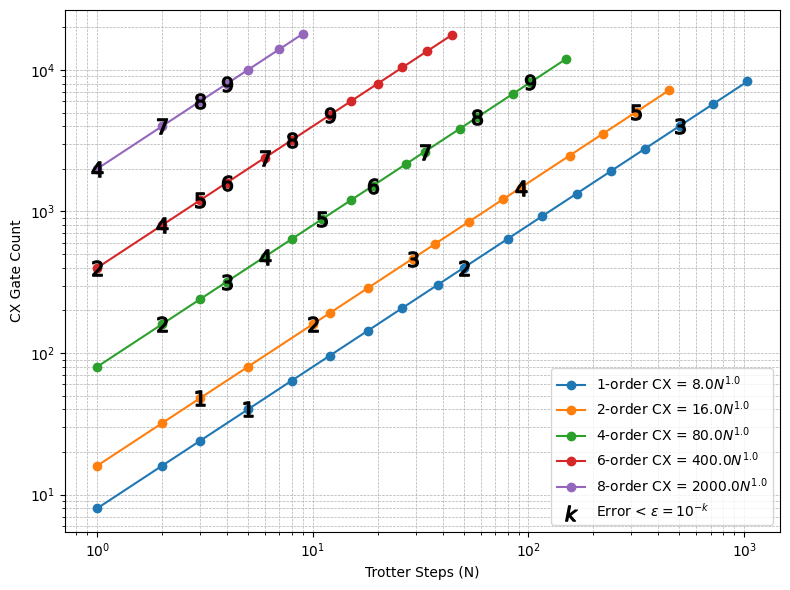

In [293]:
import numpy as np
import matplotlib.pyplot as plt

crossings = {
    1: {1:5,    2:50,   3:504,  4:5043          },
    2: {1:3,    2:10,   3:29,   4:92,   5:315  },
    4: {1:2,    2:2,    3:4,    4:6,    5:11,
        6:19,   7:33,   8:58,   9:102         },
    6: {1:1,    2:1,    3:2,    4:2,    5:3,
        6:4,    7:6,    8:8,    9:12          },
    8: {1:1,    2:1,    3:1,    4:1,    5:2,
        6:2,    7:2,    8:3,    9:4           }
}
Ns_list = [
    [1, 2, 3, 5, 8, 12, 18, 26, 38, 50, 80, 116, 167, 241, 347, 504, 720, 1036],
    [1, 2, 3, 5, 10, 12, 18, 29, 37, 53, 76, 92, 155, 221, 315, 448],
    [1, 2, 3, 4, 6, 8, 11, 15, 19, 27, 33, 48, 58, 85, 102, 150],
    [1, 2, 3, 4, 6, 8, 12, 15, 20, 26, 34, 44],
    [1, 2, 3, 4, 5, 7, 9]
]


# --- Load your summary data ---
  # object-array: one list of Ns per order
means   = cx_count_all  
markers = {
1:([5,3],[means[0][3],means[1][2]]),
2:([50,10,2,1],[means[0][9],means[1][4],means[2][1],means[3][0]]),
3:([504,29,4],[means[0][15],means[1][7],means[2][3]]),
4:([92,6,2,1],[means[1][11],means[2][4],means[3][1],means[4][0]]),
5:([315,11,3],[means[1][14],means[2][6],means[3][2]]),
6:([19,4],[means[2][8],means[3][3]]),
7:([33,6,2],[means[2][10],means[3][4],means[4][1]]),
8:([58,8,3],[means[2][12],means[3][5],means[4][2]]),
9:([102,12,4],[means[2][14],means[3][6],means[4][3]]),
}


# --- Plot ---
plt.figure(figsize=(8,6))
Cx_factors = [8.00,16.00,80.00,400.00,2000.00]
i=0
for order, Ns, mean,in zip(orders, Ns_list, means):

    plt.plot(Ns, mean, marker='o', linestyle='-', label =fr'{order}-order CX = ${Cx_factors[i]}N^{{1.0}}$')
    i+=1
for k, (xs, ys) in markers.items():
    plt.scatter(
        xs, ys,
        marker=f'${k}$',   # puts the digit “k” as the marker
        s=120,             # marker size
        c='black',         # color
        zorder=5,
    )
plt.scatter([], [],
            marker=r'$k$',
            c='black',
            s=120,
            label=r'Error < $\epsilon = 10^{-k}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Trotter Steps (N)')
plt.ylabel('CX Gate Count')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('trotter_cx_gate_count_plot')
plt.show()


In [131]:
import numpy as np

fits = []
for order, Ns, counts in zip(orders, Ns_list, cx_count_all):
    logN    = np.log10(Ns)
    logCNOT = np.log10(counts)
    slope, intercept = np.polyfit(logN, logCNOT, 1)
    # slope ≃ 1.0, intercept = log10(c_r)
    c_r = 10**intercept
    fits.append((order, slope, c_r))
    print(f"{order}‑order: slope = {slope:.3f},  CNOT(N) ≈ {c_r:.1f}·N")

1‑order: slope = 1.000,  CNOT(N) ≈ 8.0·N
2‑order: slope = 1.000,  CNOT(N) ≈ 16.0·N
4‑order: slope = 1.000,  CNOT(N) ≈ 80.0·N
6‑order: slope = 1.000,  CNOT(N) ≈ 400.0·N
8‑order: slope = 1.000,  CNOT(N) ≈ 2000.0·N


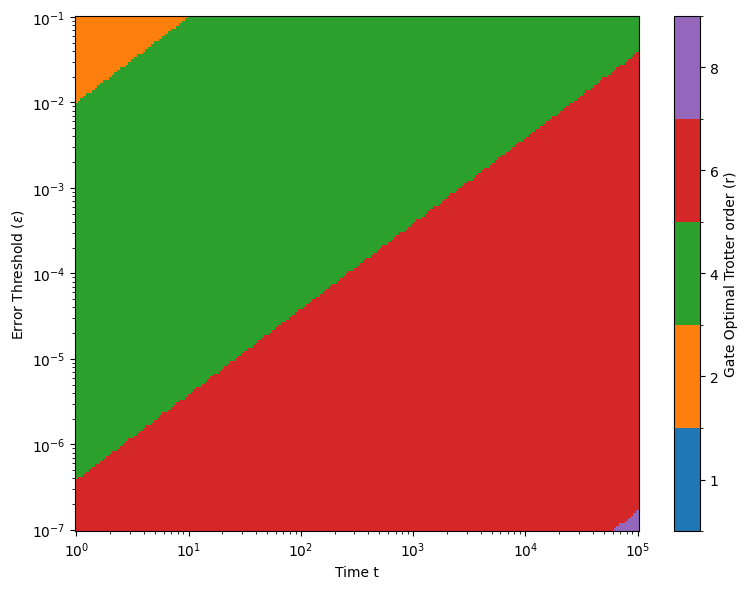

In [332]:
# 1-order
# Fitted slope = -1.025 (should ≃ -1)
# Fitted intercept = 0.422
# Estimated C ≈ 1.525e+00
# 2-order
# Fitted slope = -2.023 (should ≃ -2)
# Fitted intercept = 0.313
# Estimated C ≈ 1.368e+00
# 4-order
# Fitted slope = -4.143 (should ≃ -4)
# Fitted intercept = -0.946
# Estimated C ≈ 3.883e-01
# 6-order
# Fitted slope = -6.270 (should ≃ -6)
# Fitted intercept = -4.333
# Estimated C ≈ 1.313e-02
# 8-order
# Fitted slope = -8.230 (should ≃ -8)
# Fitted intercept = -9.674
# Estimated C ≈ 6.288e-05


from matplotlib.colors import ListedColormap, BoundaryNorm

# Define Trotter orders, CX prefactors, and C constants
rs = np.array([1, 2, 4, 6, 8])
cx_factors = np.array([8, 16, 80, 400, 2000])
Cs = np.array([1.35e+00, 1.35e+00,  2.93e-01, 1.65e-2, 9.12e-5])

# Define epsilon and time ranges
epsilons = np.logspace(-1, -7, 200)  # ε from 10⁻¹ to 10⁻⁵
ts = np.logspace(0, 5, 200)          # t from 10⁰ to 10³

# Create meshgrid (E for ε, T for t)
E, T = np.meshgrid(epsilons, ts)

# Compute gate counts for each order on the grid
gate_counts = []
for i, r in enumerate(rs):
    counts = cx_factors[i] * ((Cs[i] / E) * T**(r+1))**(1/r)
    gate_counts.append(counts)
gate_counts = np.stack(gate_counts, axis=0)

# Find optimal order (index) at each grid point
optimal = np.argmin(gate_counts, axis=0)

# Create a discrete colormap and norm
cmap = ListedColormap(plt.get_cmap('tab10').colors[:len(rs)])
norm = BoundaryNorm(np.arange(len(rs)+1)-0.5, len(rs))

# Plot the 2D color map with time on the x-axis
plt.figure(figsize=(8, 6))
mesh = plt.pcolormesh(T, E, optimal, cmap=cmap, norm=norm, shading='auto')

# Log scales and labels
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time t')
plt.ylabel(r'Error Threshold $(\epsilon)$')

# Discrete colorbar
cbar = plt.colorbar(mesh, boundaries=np.arange(len(rs)+1)-0.5, ticks=np.arange(len(rs)))
cbar.set_ticklabels(rs)
cbar.set_label('Gate Optimal Trotter order (r)')

# plt.title('Optimal Trotter Order as a function of t and ε')
plt.tight_layout()
plt.savefig("Final_Optimal_Trotter_Order")
plt.show()



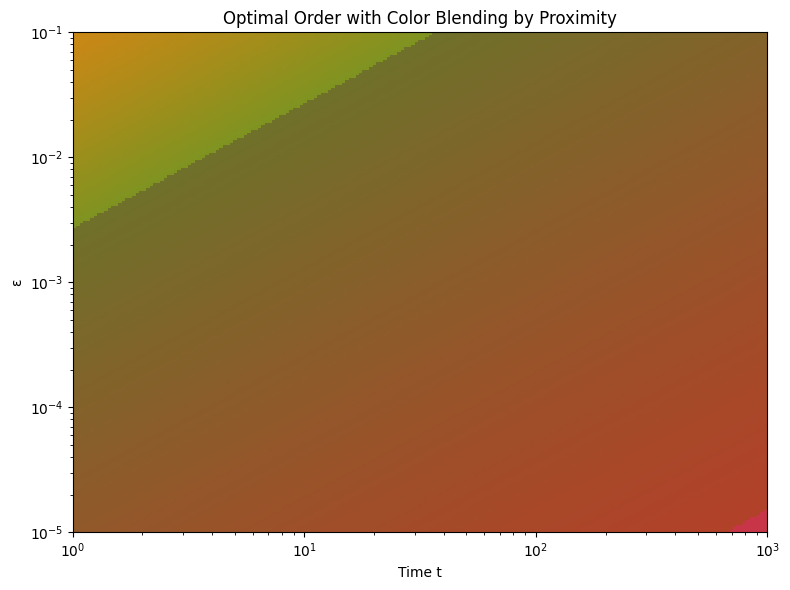

In [250]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters for Trotter orders ---
rs = np.array([1, 2, 4, 6, 8])
cx_factors = np.array([8, 16, 80, 400, 2000])
Cs = np.array([1.525e+00, 1.368e+00, 3.883e-01, 1.313e-3, 6.288e-5])

# Define epsilon and time ranges
epsilons = np.logspace(-1, -5, 200)  # ε from 10⁻¹ to 10⁻⁵
ts = np.logspace(0, 3, 200)          # t from 10⁰ to 10³
E, T = np.meshgrid(epsilons, ts)     # grid for evaluations

# --- Suppose we have known (exact) gate counts at t=1 for each (r, ε) ---
# Replace this placeholder with your measured or computed values:
# shape: (len(rs), len(epsilons))
gate_at_1 = np.stack([
    cx_factors[i] * ((Cs[i] / epsilons) * 1**(rs[i]+1))**(1/rs[i])
    for i in range(len(rs))
], axis=0)

# --- 1) Calibrate C per (r, ε) so f_asym(1) = gate_at_1 ---
C_fit = epsilons[None, :] * (gate_at_1 / cx_factors[:, None])**rs[:, None]

# --- 2) Define asymptotic and smooth interpolated functions ---
def f_asymptotic(r_idx, E, T):
    """Asymptotic form with fitted C_fit."""
    return cx_factors[r_idx] * ((C_fit[r_idx][None, :] / E) * T**(rs[r_idx] + 1))**(1/rs[r_idx])

def f_smooth(r_idx, E, T, t0=10.0, beta=3.0):
    """Smooth blend between gate_at_1 and asymptotic form."""
    asym = f_asymptotic(r_idx, E, T)
    # logistic blending weight: 0 at t=1, ~1 for t >> t0
    weight = 1 / (1 + np.exp(-beta * (np.log10(T) - np.log10(t0))))
    # reshape gate_at_1 for broadcasting: shape (1, len(epsilons))
    g1 = gate_at_1[r_idx][None, :]
    return (1 - weight) * g1 + weight * asym

# --- 3) Compute smoothed gate counts tensor ---
smoothed_counts = np.stack([
    f_smooth(i, E, T)
    for i in range(len(rs))
], axis=0)  # shape: (orders, t_points, eps_points)

# --- 4) Determine optimal order on the smoothed data ---
optimal_smooth = np.argmin(smoothed_counts, axis=0)

# --- 5) Plot the result (time on x-axis) ---
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(plt.get_cmap('tab10').colors[:len(rs)])
norm = BoundaryNorm(np.arange(len(rs)+1)-0.5, len(rs))

plt.figure(figsize=(8, 6))
mesh = plt.pcolormesh(T, E, optimal_smooth, cmap=cmap, norm=norm, shading='auto')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Time t'); plt.ylabel('ε')
cbar = plt.colorbar(mesh, boundaries=np.arange(len(rs)+1)-0.5, ticks=np.arange(len(rs)))
cbar.set_ticklabels(rs); cbar.set_label('Optimal Trotter order r')
plt.title('Optimal Order with Smooth Calibration at t=1')
plt.tight_layout()
plt.show()
